# FraudGuard Pivot: Online Payment Fraud Detection (CS 439 Stage 1)

**Team:** Alban Gurra, Daniel Liu, Milan T Patel — Group 5

## Project Description

PromoGuard, our original project, targeted promo-code abuse using an unsupervised approach. The dataset proved too flawed for reliable analysis, so the team pivoted to a **supervised** fraud-detection problem: classifying legitimate vs. fraudulent online payment transactions using the *Online Payment Fraud Detection* dataset (Kaggle). The end goal is an interactive system that scores incoming transactions and surfaces high-risk payments for review.

# Necessary Libraries and Dependencies

In [1]:
import os, sys, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              average_precision_score, roc_auc_score,
                              precision_recall_curve)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

PATH = "onlinefraud.csv"
print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| sklearn", __import__("sklearn").__version__)
print("Platform:", platform.platform())

Python 3.14.7 | pandas 3.0.5 | numpy 2.5.3 | sklearn 1.9.1
Platform: macOS-27.0.1-arm64-arm-64bit-Mach-O


# Exploratory Data Analysis

## Dataset Short Description

**Online Payment Fraud Detection** (Kaggle). A single relational table of ~6.36M online payment transactions simulated over a 30-day period (`step` = hour index, 1–744). Each row is one transaction with sender/recipient anonymized account IDs, balances before/after, transaction type, amount, and fraud labels (`isFraud`, `isFlaggedFraud`).

| Column | Description |
|---|---|
| step | Time unit (1 step = 1 hour) |
| type | Transaction type: CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER |
| amount | Transaction amount |
| nameOrig | Originating account ID |
| oldbalanceOrg / newbalanceOrig | Sender balance before / after |
| nameDest | Recipient account ID |
| oldbalanceDest / newbalanceDest | Recipient balance before / after |
| isFraud | Fraud label (target) |
| isFlaggedFraud | Legacy flag (attempt > $200k) |

### Raw Dataset Size (on disk)

In [2]:
size_bytes = os.path.getsize(PATH)
print(f"File: {PATH}")
print(f"Size on disk: {size_bytes:,} bytes ({size_bytes/1e6:.1f} MB)")

# count records fast
n_lines = sum(1 for _ in open(PATH, 'rb'))
n_records = n_lines - 1  # minus header
print(f"Records (lines - header): {n_records:,}")
print(f"Dataset Record Size (CSV text bytes/record): {size_bytes/n_records:.1f} bytes/record")

File: onlinefraud.csv
Size on disk: 493,534,783 bytes (493.5 MB)


Records (lines - header): 6,362,620
Dataset Record Size (CSV text bytes/record): 77.6 bytes/record


### Load, Inspect, and Clean

In [3]:
t0 = time.time()
df = pd.read_csv(PATH, dtype={"type": "category"})
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} cols in {time.time()-t0:.1f}s")
df["isFraud"] = df["isFraud"].astype("int8")
df["isFlaggedFraud"] = df["isFlaggedFraud"].astype("int8")
print("\nDtypes:\n", df.dtypes)
miss = df.isna().sum()
print("\nMissing values:\n", miss[miss > 0] if (miss > 0).any() else "none")
print("\nMemory footprint:", f"{df.memory_usage(deep=True).sum()/1e6:.0f} MB")
print(f"Entry Size (in-memory bytes/record): {df.memory_usage(deep=True).sum()/len(df):.0f} bytes/row")

Loaded 6,362,620 rows x 11 cols in 5.9s

Dtypes:
 step                 int64
type              category
amount             float64
nameOrig               str
oldbalanceOrg      float64
newbalanceOrig     float64
nameDest               str
oldbalanceDest     float64
newbalanceDest     float64
isFraud               int8
isFlaggedFraud        int8
dtype: object



Missing values:
 none



Memory footprint: 1081 MB
Entry Size (in-memory bytes/record): 170 bytes/row


In [ ]:
# Entry size = bytes for ONE value in a column (record size = sum over the row)
for c, t in df.dtypes.items():
    try:
        print(f"{c:>15}: {str(t):<9} -> {np.dtype(t).itemsize} bytes per entry")
    except TypeError:
        print(f"{c:>15}: {str(t):<9} -> variable (category codes / text IDs)")

### Dataset Snapshots (single table: `transactions`)

In [4]:
df.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0


*Fraud examples (all 8,213 look like this: sender balance drained, destination is a `C` account):*

In [ ]:
df[df["isFraud"] == 1].head(10)

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,6362620.0,2.433972e+02,1.423320e+02,1.0,156.00,239.000,3.350000e+02,7.430000e+02
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.57,74871.940,2.087215e+05,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.00,14208.000,1.073152e+05,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.00,0.000,1.442584e+05,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.00,132705.665,9.430367e+05,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.00,214661.440,1.111909e+06,3.561793e+08
isFraud,6362620.0,1.290820e-03,3.590480e-02,0.0,0.00,0.000,0.000000e+00,1.000000e+00
isFlaggedFraud,6362620.0,2.514687e-06,1.585775e-03,0.0,0.00,0.000,0.000000e+00,1.000000e+00


In [6]:
df.nunique().sort_values()

isFraud                 2
isFlaggedFraud          2
type                    5
step                  743
oldbalanceOrg     1845844
newbalanceOrig    2682586
nameDest          2722362
newbalanceDest    3555499
oldbalanceDest    3614697
amount            5316900
nameOrig          6353307
dtype: int64

### Frequency Counts

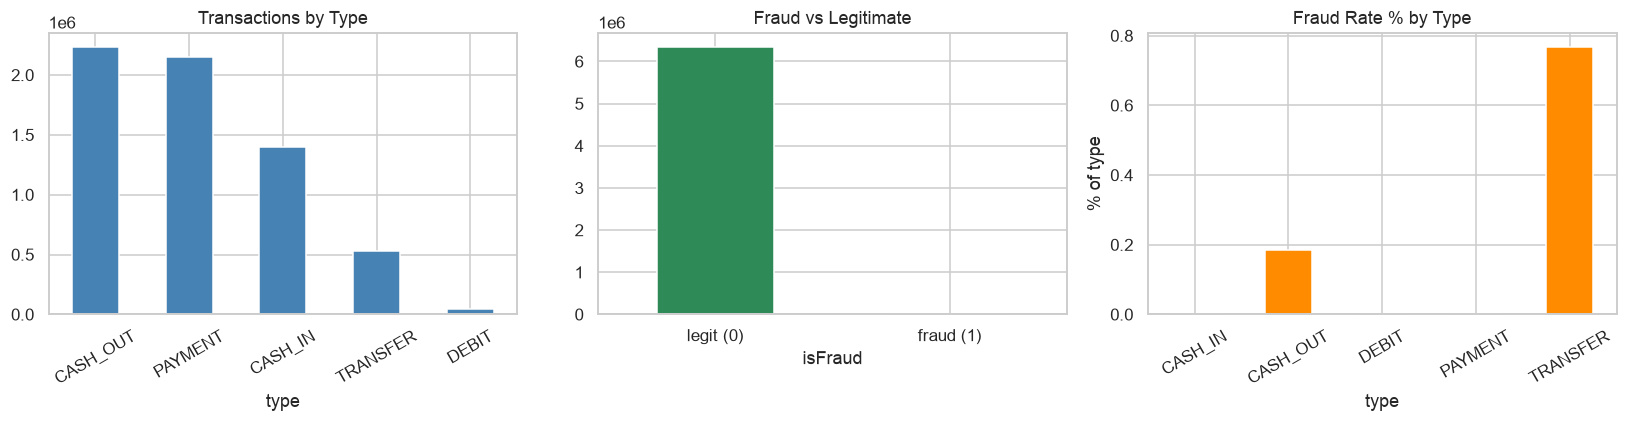

Fraud counts by type:
            sum    count      mean
type                             
CASH_IN      0  1399284  0.000000
CASH_OUT  4116  2237500  0.001840
DEBIT        0    41432  0.000000
PAYMENT      0  2151495  0.000000
TRANSFER  4097   532909  0.007688

isFlaggedFraud counts:
 isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["type"].value_counts().plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Transactions by Type"); axes[0].set_xlabel("type"); axes[0].tick_params(axis='x', rotation=30)

df["isFraud"].value_counts().plot.bar(ax=axes[1], color=["seagreen", "crimson"])
axes[1].set_title("Fraud vs Legitimate"); axes[1].set_xticklabels(["legit (0)", "fraud (1)"], rotation=0)

ct = pd.crosstab(df["type"], df["isFraud"], normalize="index") * 100
ct[1].plot.bar(ax=axes[2], color="darkorange")
axes[2].set_title("Fraud Rate % by Type"); axes[2].set_ylabel("% of type"); axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

print("Fraud counts by type:\n", df.groupby("type")["isFraud"].agg(["sum", "count", "mean"]))
print("\nisFlaggedFraud counts:\n", df["isFlaggedFraud"].value_counts())

### Distributions (Histograms, Mean, Standard Deviation)

                      mean         std  min     median           max
step                243.40      142.33  1.0     239.00  7.430000e+02
amount           179861.90   603858.23  0.0   74871.94  9.244552e+07
oldbalanceOrg    833883.10  2888242.67  0.0   14208.00  5.958504e+07
newbalanceOrig   855113.67  2924048.50  0.0       0.00  4.958504e+07
oldbalanceDest  1100701.67  3399180.11  0.0  132705.66  3.560159e+08
newbalanceDest  1224996.40  3674128.94  0.0  214661.44  3.561793e+08


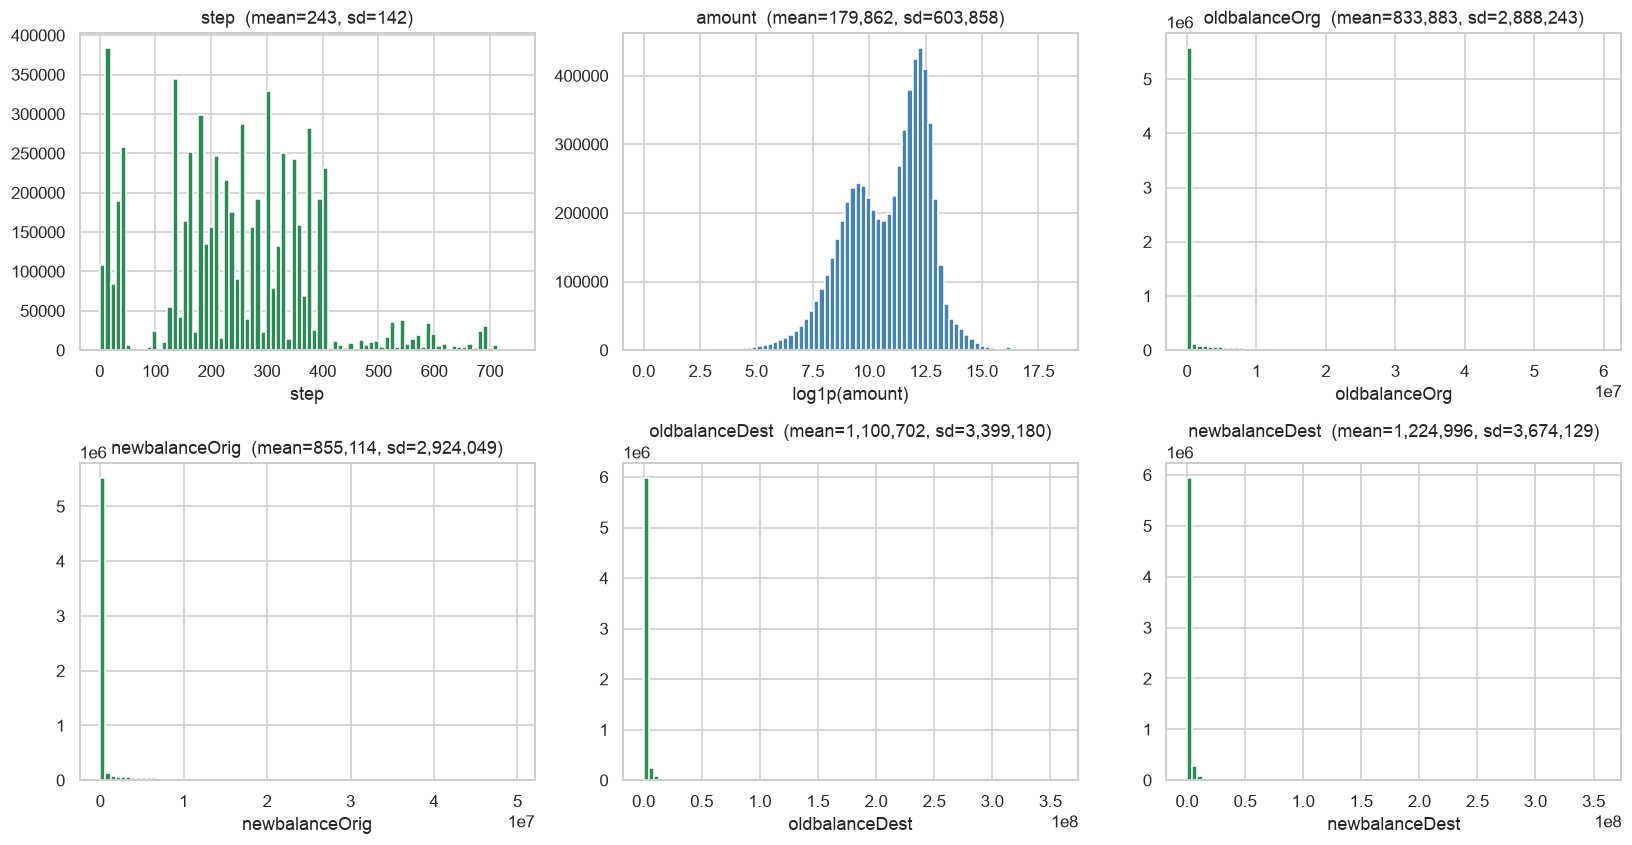

In [8]:
num_cols = ["step", "amount", "oldbalanceOrg", "newbalanceOrig",
            "oldbalanceDest", "newbalanceDest"]
stats = df[num_cols].agg(["mean", "std", "min", "median", "max"]).T
print(stats.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, num_cols):
    if c == "amount":
        ax.hist(np.log1p(df[c]), bins=80, color="steelblue")
        ax.set_xlabel("log1p(amount)")
    else:
        ax.hist(df[c].clip(lower=0), bins=80, color="seagreen")
        ax.set_xlabel(c)
    ax.set_title(f"{c}  (mean={df[c].mean():,.0f}, sd={df[c].std():,.0f})")
plt.tight_layout(); plt.show()

### Pair Plot
*(balanced sample: frauds are only 0.13% of data, so we oversample them for visibility)*

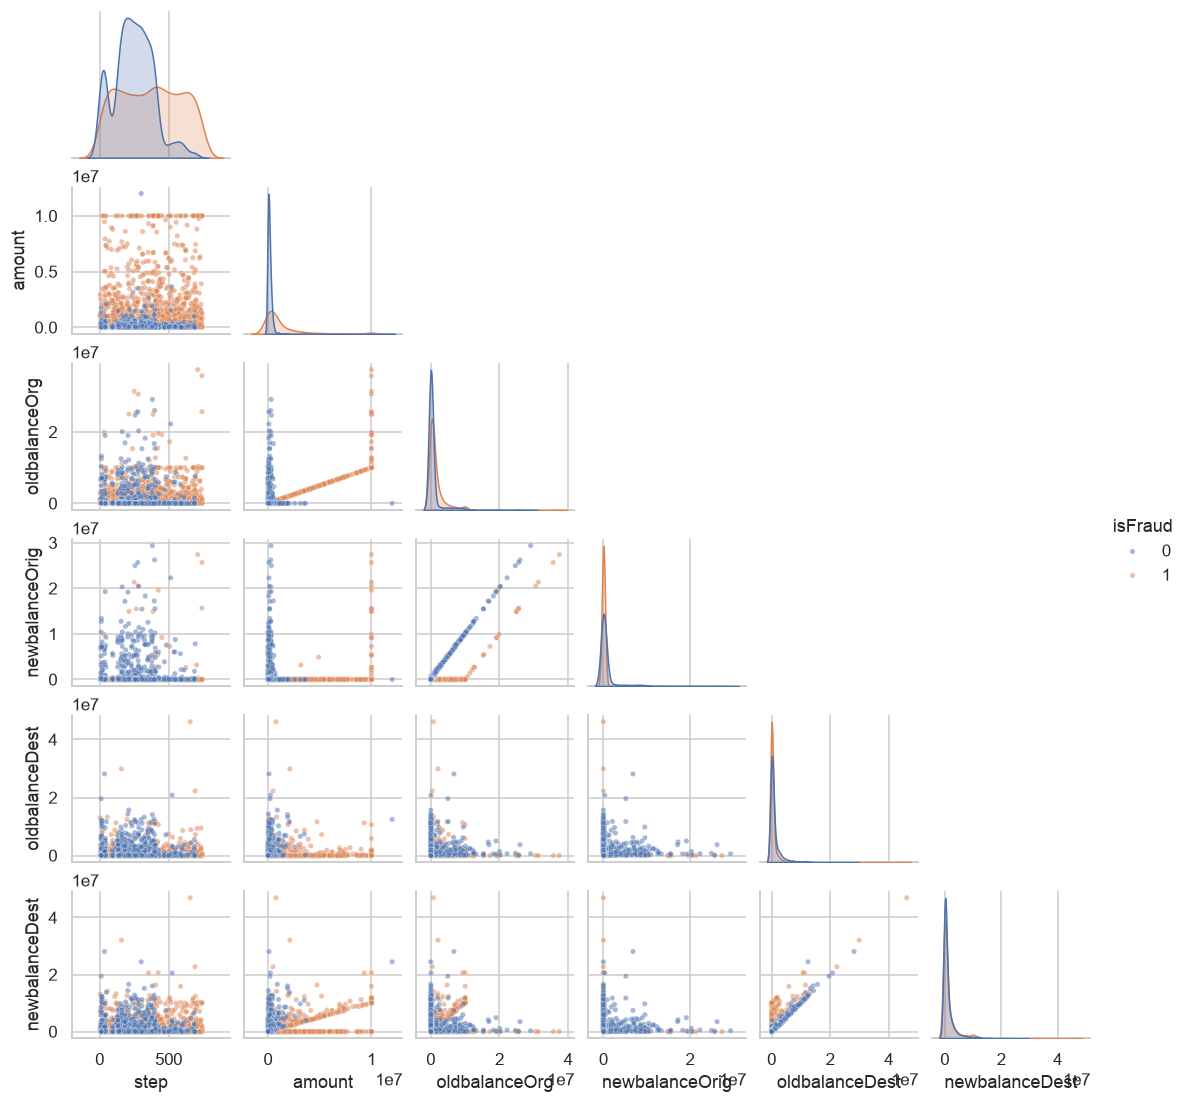

In [9]:
pair_cols = ["step", "amount", "oldbalanceOrg", "newbalanceOrig",
             "oldbalanceDest", "newbalanceDest"]
fraud_s = df[df.isFraud == 1].sample(1500, random_state=42)
legit_s = df[df.isFraud == 0].sample(1500, random_state=42)
pair_df = pd.concat([fraud_s[pair_cols + ["isFraud"]], legit_s[pair_cols + ["isFraud"]]])
sns.pairplot(pair_df, hue="isFraud", corner=True, height=1.7,
             plot_kws=dict(s=12, alpha=0.5))
plt.show()

### z-Score Distributions
*z = (x − mean) / SD; |z| > 3 is a common outlier threshold*

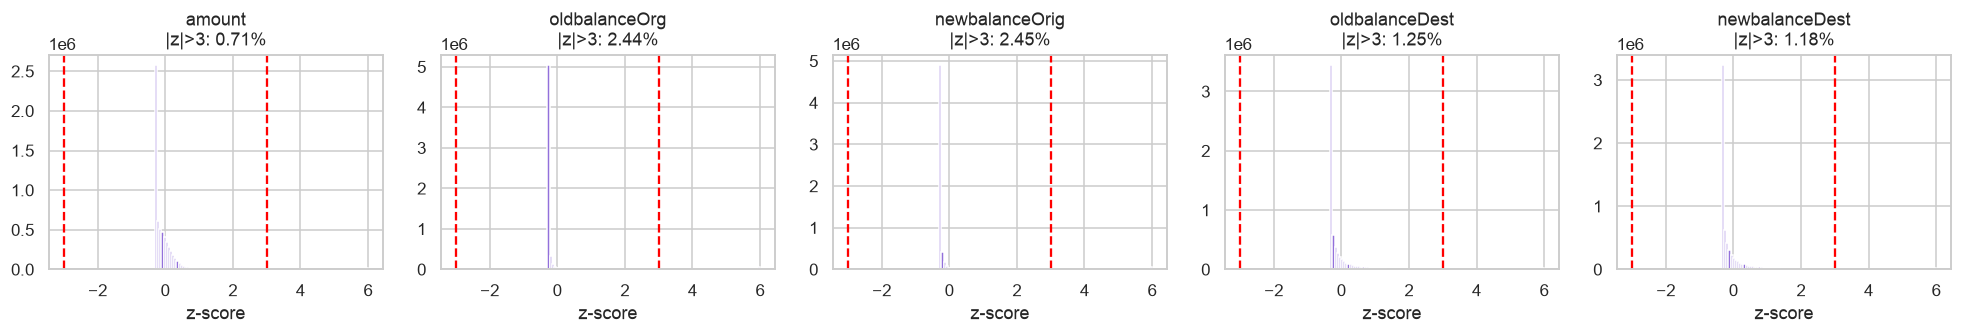

amount z>3 (high): 44,945  |  z<-3 (low): 0
amount max z-score: 152.8


In [10]:
z_cols = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
fig, axes = plt.subplots(1, len(z_cols), figsize=(18, 3.2))
for ax, c in zip(axes, z_cols):
    z = (df[c] - df[c].mean()) / df[c].std()
    ax.hist(z.clip(-6, 6), bins=100, color="mediumpurple")
    ax.axvline(3, color="red", ls="--"); ax.axvline(-3, color="red", ls="--")
    ax.set_title(f"{c}\n|z|>3: {(z.abs() > 3).mean()*100:.2f}%")
    ax.set_xlabel("z-score")
plt.tight_layout(); plt.show()

z_amount = (df["amount"] - df["amount"].mean()) / df["amount"].std()
print(f"amount z>3 (high): {(z_amount > 3).sum():,}  |  z<-3 (low): {(z_amount < -3).sum():,}")
print(f"amount max z-score: {z_amount.max():.1f}")

### Derived Features & Fraud Patterns

In [11]:
df["balanceDeltaOrig"] = df["newbalanceOrig"] - df["oldbalanceOrg"]
df["balanceDeltaDest"] = df["newbalanceDest"] - df["oldbalanceDest"]
df["destPrefix"] = df["nameDest"].str[0]
df["origPrefix"] = df["nameOrig"].str[0]

print("Destination prefix distribution (all / fraud only):")
print(pd.crosstab(df["destPrefix"], df["isFraud"], normalize="columns") * 100)

f = df[df.isFraud == 1]
l = df[df.isFraud == 0]
print("\nAmount stats — fraud vs legit:")
print(pd.Series({"fraud_mean": f.amount.mean(), "legit_mean": l.amount.mean(),
                 "fraud_median": f.amount.median(), "legit_median": l.amount.median()}).round(2))

# fraud rate by hour-of-step decile
step_bins = pd.cut(df["step"], bins=12)
print("\nFraud rate by step decile (%):")
print((df.groupby(step_bins, observed=True)["isFraud"].mean() * 100).round(3))

# balance consistency check: does amount ~= -balanceDeltaOrig for cash_out?
co = df[df.type == "CASH_OUT"]
print("\nCASH_OUT rows where amount != oldbalanceOrg - newbalanceOrig:",
      int((co.amount != (co.oldbalanceOrg - co.newbalanceOrig)).sum()))

Destination prefix distribution (all / fraud only):


isFraud             0      1
destPrefix                  
C           66.141687  100.0
M           33.858313    0.0



Amount stats — fraud vs legit:
fraud_mean      1467967.30
legit_mean       178197.04
fraud_median     441423.44
legit_median      74684.72
dtype: float64

Fraud rate by step decile (%):


step
(0.258, 62.833]       0.071
(62.833, 124.667]     1.777
(124.667, 186.5]      0.058
(186.5, 248.333]      0.071
(248.333, 310.167]    0.060
(310.167, 372.0]      0.072
(372.0, 433.833]      0.098
(433.833, 495.667]    1.393
(495.667, 557.5]      0.564
(557.5, 619.333]      0.667
(619.333, 681.167]    2.236
(681.167, 743.0]      1.161
Name: isFraud, dtype: float64

CASH_OUT rows where amount != oldbalanceOrg - newbalanceOrig: 2098953


### Supervised Baseline (preview of Stage 2 modeling)
*Random Forest on a stratified sample — fraud is 0.13% of rows, so we keep all frauds + 120k legit.*

              precision    recall  f1-score   support

       legit     0.9981    0.9986    0.9983     36000
       fraud     0.9796    0.9720    0.9758      2464

    accuracy                         0.9969     38464
   macro avg     0.9888    0.9853    0.9871     38464
weighted avg     0.9969    0.9969    0.9969     38464

PR-AUC: 0.9966 | ROC-AUC: 0.9992


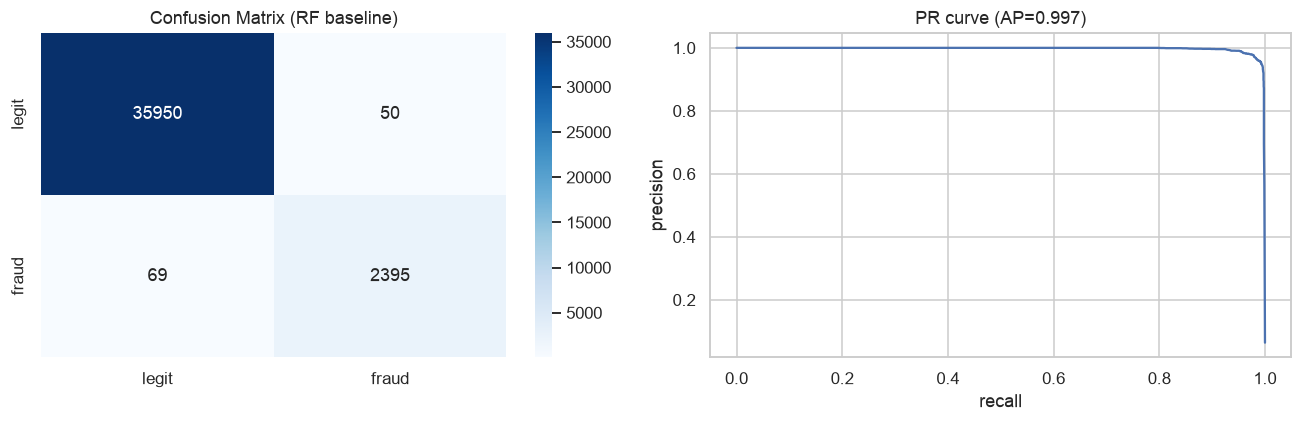

Top features:
 balanceDeltaOrig    0.3754
oldbalanceOrg       0.1898
newbalanceOrig      0.1297
amount              0.1126
destPrefix_M        0.0637
balanceDeltaDest    0.0624
step                0.0358
newbalanceDest      0.0191
oldbalanceDest      0.0114
dtype: float64


In [12]:
feat_cols = ["step", "amount", "oldbalanceOrg", "newbalanceOrig",
             "oldbalanceDest", "newbalanceDest", "balanceDeltaOrig",
             "balanceDeltaDest", "destPrefix", "origPrefix"]
X = pd.get_dummies(df[feat_cols], columns=["destPrefix", "origPrefix"], drop_first=True)
y = df["isFraud"]

idx_f = df.index[df.isFraud == 1].to_numpy()
idx_l = df[df.isFraud == 0].sample(120_000, random_state=42).index.to_numpy()
idx = np.concatenate([idx_f, idx_l])
X_s, y_s = X.loc[idx], y.loc[idx]
X_tr, X_te, y_tr, y_te = train_test_split(
    X_s, y_s, test_size=0.3, stratify=y_s, random_state=42)

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)
rf.fit(X_tr, y_tr)
proba = rf.predict_proba(X_te)[:, 1]
pred = rf.predict(X_te)

print(classification_report(y_te, pred, target_names=["legit", "fraud"], digits=4))
print("PR-AUC:", round(average_precision_score(y_te, proba), 4),
      "| ROC-AUC:", round(roc_auc_score(y_te, proba), 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cm = confusion_matrix(y_te, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["legit", "fraud"], yticklabels=["legit", "fraud"])
axes[0].set_title("Confusion Matrix (RF baseline)")
p, r, _ = precision_recall_curve(y_te, proba)
axes[1].plot(r, p); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title(f"PR curve (AP={average_precision_score(y_te, proba):.3f})")
plt.tight_layout(); plt.show()

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
print("Top features:\n", imp.round(4))

## Supervised Learning Procedure

**What "supervised" means here:** every transaction already has the answer attached (`isFraud` = 1 or 0). The model sees many transactions *with* their answers, learns which patterns go with fraud, then is judged on transactions it has never seen.

1. **Define the task.** Binary classification. Features **X** = the transaction attributes (`amount`, balances, `type`, engineered features). Target **y** = `isFraud`.
2. **Engineer features.** Create signals the raw columns hide: balance deltas, destination prefix (`C` account vs `M` merchant), type dummies. Models only see numbers, so categories become dummy columns.
3. **Handle the imbalance for training.** Only 0.13% of rows are fraud. A model trained on raw data can score 99.87% accuracy by always saying "legit." So we keep **all** frauds and a **sample** of legit rows (about 6% fraud), and use `class_weight="balanced_subsample"` so a missed fraud costs more than a missed legit row.
4. **Split into train and test.** The model may only learn from the training part; the test part is locked away until the end. The baseline above used a *random* split. A fraud system predicts the *future*, so the stronger test is a **temporal split**: train on early `step`s, test on later ones.
5. **Fit.** A Random Forest builds many decision trees, each trained on a random subset of rows and features, and averages their votes. `predict_proba` returns a fraud probability, our risk score.
6. **Pick a threshold.** Turn the score into an alert (`score >= t`). Lower `t` catches more fraud but creates more false alarms; this tradeoff is the precision–recall curve.
7. **Evaluate on the test set.** Use PR-AUC, precision, recall, F1 and the confusion matrix, never accuracy. Compare against a no-skill baseline (= fraud rate) and a simpler model (logistic regression).
8. **Inspect.** Feature importances show what the model relies on. Check that the top features are sensible and not leakage (a feature that effectively contains the answer).

**Why the cell below matters:** the random-split test set is ~6.4% fraud, so its precision (0.98) does not reflect production, where 99.87% of traffic is legit. Evaluating on a *later* time window with *all* of its legit rows gives the honest picture.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score

CUT = 500                                   # train on step <= CUT, test on step > CUT
is_tr = df["step"] <= CUT
n_leg = min(120_000, int((is_tr & (df.isFraud == 0)).sum()))
tr_idx = df.index[is_tr & (df.isFraud == 1)].union(
         df[is_tr & (df.isFraud == 0)].sample(n_leg, random_state=42).index)
te_idx = df.index[~is_tr]                   # ALL later rows: natural fraud rate
Xtr, ytr, Xte, yte = X.loc[tr_idx], y.loc[tr_idx], X.loc[te_idx], y.loc[te_idx]
print(f"Train: {len(Xtr):,} rows, {ytr.mean()*100:.2f}% fraud (resampled)")
print(f"Test : {len(Xte):,} rows, {yte.mean()*100:.3f}% fraud (natural, later in time)")

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=42),
}
rows, probas = [], {}
for name, m in models.items():
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]; probas[name] = p
    pred = (p >= 0.5).astype(int)
    pr, rc, _ = precision_recall_curve(yte, p)
    rows.append({"model": name,
                 "PR-AUC": average_precision_score(yte, p), "ROC-AUC": roc_auc_score(yte, p),
                 "precision@0.5": precision_score(yte, pred), "recall@0.5": recall_score(yte, pred),
                 "F1@0.5": f1_score(yte, pred),
                 "precision @ recall>=0.90": pr[rc >= 0.90].max() if (rc >= 0.90).any() else float("nan"),
                 "alerts raised": int(pred.sum())})
res = pd.DataFrame(rows).set_index("model").round(4)
print(res.T)
print(f"\nNo-skill PR-AUC (= test fraud rate): {yte.mean():.4f}")
print("Confusion matrix, Random Forest (rows = actual, cols = predicted):")
print(confusion_matrix(yte, (probas["Random Forest"] >= 0.5).astype(int)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, p in probas.items():
    pr, rc, _ = precision_recall_curve(yte, p); axes[0].plot(rc, pr, label=f"{name} (AP={average_precision_score(yte, p):.3f})")
axes[0].axhline(yte.mean(), ls="--", c="gray", label="no skill")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Temporal split: PR curves"); axes[0].legend(fontsize=8)
imp_t = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values().tail(10)
imp_t.plot.barh(ax=axes[1], color="steelblue"); axes[1].set_title("Random Forest feature importance (temporal model)")
plt.tight_layout(); plt.show()

## Data Transformations Flowchart

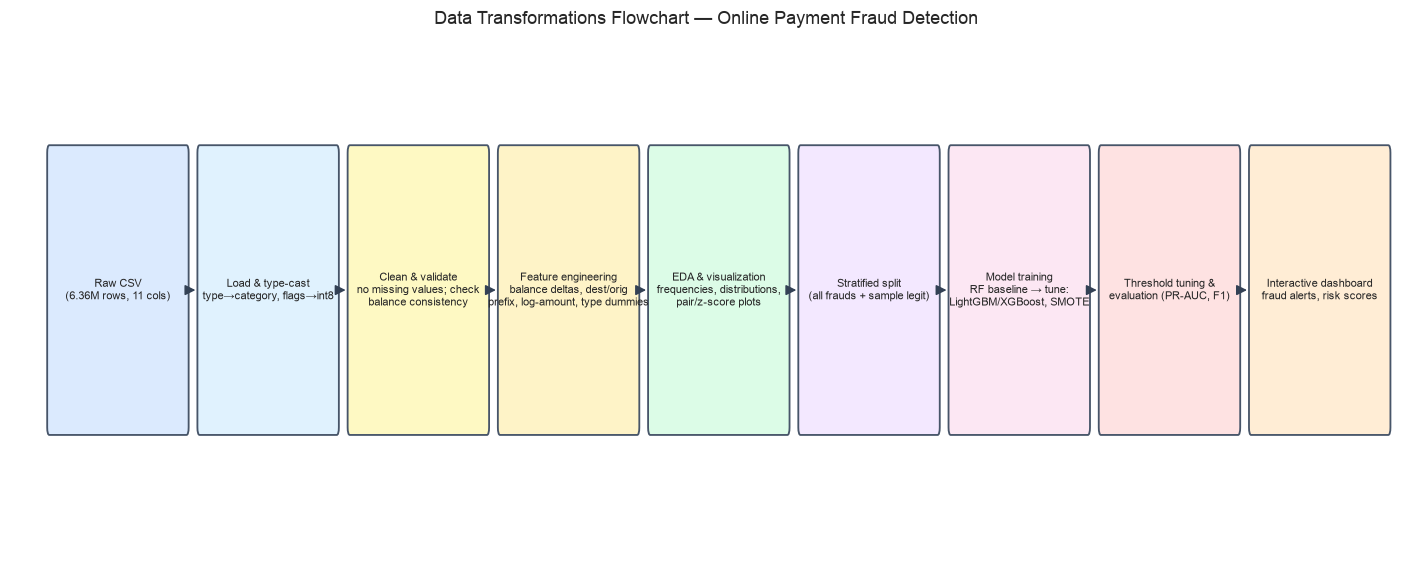

In [13]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

steps = [
    ("Raw CSV\n(6.36M rows, 11 cols)", "#dbeafe"),
    ("Load & type-cast\ntype→category, flags→int8", "#e0f2fe"),
    ("Clean & validate\nno missing values; check\nbalance consistency", "#fef9c3"),
    ("Feature engineering\nbalance deltas, dest/orig\nprefix, log-amount, type dummies", "#fef3c7"),
    ("EDA & visualization\nfrequencies, distributions,\npair/z-score plots", "#dcfce7"),
    ("Stratified split\n(all frauds + sample legit)", "#f3e8ff"),
    ("Model training\nRF baseline → tune:\nLightGBM/XGBoost, SMOTE", "#fce7f3"),
    ("Threshold tuning &\nevaluation (PR-AUC, F1)", "#fee2e2"),
    ("Interactive dashboard\nfraud alerts, risk scores", "#ffedd5"),
]
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.axis("off")
n = len(steps); W, H, gap = 1.25, 0.72, 0.12
x0, y0 = 0.35, 0.75
for i, (label, color) in enumerate(steps):
    x = x0 + i * (W + gap)
    box = FancyBboxPatch((x, y0 - H/2), W, H, boxstyle="round,pad=0.02",
                         fc=color, ec="#475569", lw=1.2)
    ax.add_patch(box)
    ax.text(x + W/2, y0, label, ha="center", va="center", fontsize=7.5)
    if i < n - 1:
        ax.add_patch(FancyArrowPatch((x + W + 0.01, y0), (x + W + gap - 0.01, y0),
                                     arrowstyle="-|>", mutation_scale=14, color="#334155"))
ax.set_xlim(0, x0 + n * (W + gap)); ax.set_ylim(0, 1.4)
ax.set_title("Data Transformations Flowchart — Online Payment Fraud Detection",
             fontsize=12, pad=12)
plt.tight_layout(); plt.show()

## Exploration Algorithms Used

**Pivot rationale:** PromoGuard's unsupervised approach (isolation forests, k-means on hand-built risk features) produced unstable results on a flawed dataset. The new dataset ships with ground-truth labels (`isFraud`), so we switched to **supervised classification**, which is far better suited to fraud detection and gives us real evaluation metrics.

**Algorithms planned / used:**
- **Baseline:** Random Forest with `class_weight="balanced_subsample"` (handles the 0.13% fraud rate)
- **Stage 2 candidates:** Gradient boosting (LightGBM/XGBoost — standard for tabular fraud), logistic regression for interpretability, optional SMOTE/class-weight tuning
- **Threshold tuning** on the precision–recall curve to trade false positives vs. missed fraud
- Unsupervised methods (isolation forest, LOF) retained only as a comparison baseline, not the primary approach

## Computational Platform and Software Libraries Used

In [14]:
import sklearn, matplotlib, seaborn
print("OS:", platform.platform())
print("Python:", sys.version.split()[0])
for name, mod in [("pandas", pd), ("numpy", np), ("matplotlib", matplotlib),
                  ("seaborn", sns), ("scikit-learn", sklearn)]:
    print(f"{name:>12}: {mod.__version__}")
print("Hardware: Apple Silicon MacBook (local execution; dataset fits in RAM)")

OS: macOS-27.0.1-arm64-arm-64bit-Mach-O
Python: 3.14.7
      pandas: 3.0.5
       numpy: 2.5.3
  matplotlib: 3.11.1
     seaborn: 0.13.2
scikit-learn: 1.9.1
Hardware: Apple Silicon MacBook (local execution; dataset fits in RAM)


## Gantt Chart — Division of Labor & Timeline
*(16-week CS 439 schedule; adjust dates to your course calendar)*

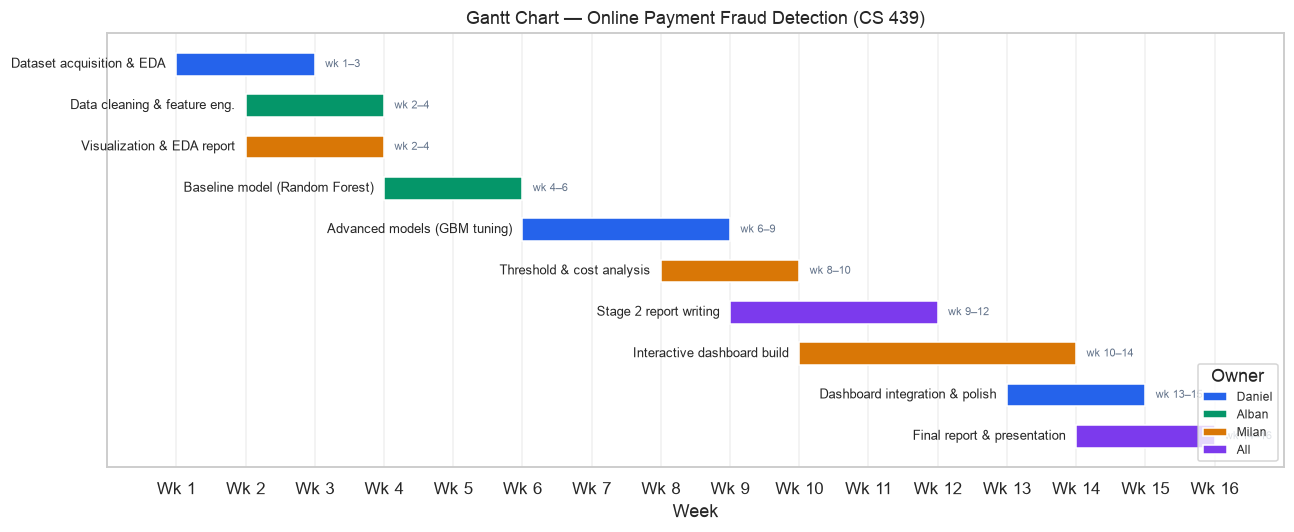

In [15]:
tasks = [
    # (label, start_week, end_week, member)
    ("Dataset acquisition & EDA",        1,  3, "Daniel"),
    ("Data cleaning & feature eng.",     2,  4, "Alban"),
    ("Visualization & EDA report",       2,  4, "Milan"),
    ("Baseline model (Random Forest)",   4,  6, "Alban"),
    ("Advanced models (GBM tuning)",     6,  9, "Daniel"),
    ("Threshold & cost analysis",        8, 10, "Milan"),
    ("Stage 2 report writing",           9, 12, "All"),
    ("Interactive dashboard build",     10, 14, "Milan"),
    ("Dashboard integration & polish",  13, 15, "Daniel"),
    ("Final report & presentation",     14, 16, "All"),
]
members = ["Daniel", "Alban", "Milan", "All"]
colors = {"Daniel": "#2563eb", "Alban": "#059669", "Milan": "#d97706", "All": "#7c3aed"}
fig, ax = plt.subplots(figsize=(12, 5))
ylabels = []
for i, (label, s, e, who) in enumerate(tasks):
    y = len(tasks) - i
    ax.barh(y, e - s, left=s, height=0.55, color=colors[who],
            edgecolor="white", label=who if who not in [t[3] for t in tasks[:i]] else None)
    ax.text(s - 0.15, y, label, ha="right", va="center", fontsize=8.5)
    ax.text(e + 0.15, y, f"wk {s}–{e}", va="center", fontsize=7, color="#64748b")
    if who not in ylabels: ylabels.append(who)
ax.set_yticks([]); ax.set_xlim(0, 17)
ax.set_xticks(range(1, 17)); ax.set_xticklabels([f"Wk {w}" for w in range(1, 17)])
ax.set_xlabel("Week"); ax.grid(axis="x", alpha=0.3)
ax.set_title("Gantt Chart — Online Payment Fraud Detection (CS 439)")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, title="Owner", loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## Visualization Samples
Key plots produced above (re-used as presentation visuals):

1. **Frequency counts** — transactions by type, fraud vs. legit, fraud-rate % by type
2. **Distributions** — histograms + mean/SD table for `amount` and all balance columns (log-scale for amount)
3. **Pair plot** — 6 numeric features, balanced fraud/legit sample, colored by `isFraud`
4. **z-Score distributions** — amount & balances, ±3σ outlier bands
5. **Fraud pattern analysis** — destination prefix × fraud crosstab, amount fraud-vs-legit, fraud rate by step decile
6. **Baseline results** — confusion matrix, PR curve, feature importances
7. **Dashboard mock-up** (below)

## Dashboard Mock-up

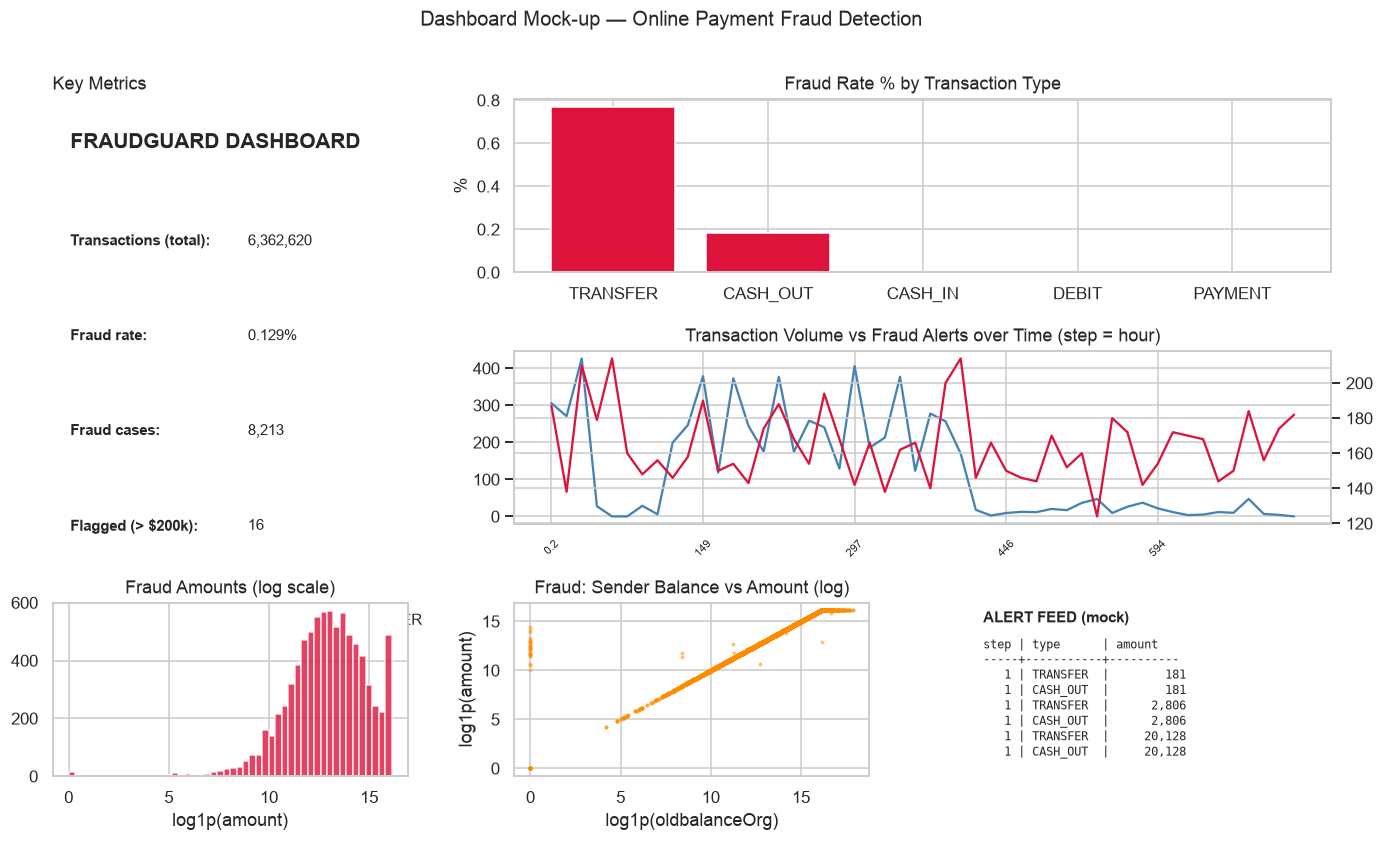

In [16]:
fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(3, 3, hspace=0.45, wspace=0.3)

# KPI panel
ax_kpi = fig.add_subplot(gs[:, 0])
ax_kpi.axis("off")
ax_kpi.text(0.05, 0.95, "FRAUDGUARD DASHBOARD", fontsize=14, weight="bold", va="top")
kpis = [
    ("Transactions (total)", f"{len(df):,}"),
    ("Fraud rate", f"{df.isFraud.mean()*100:.3f}%"),
    ("Fraud cases", f"{int(df.isFraud.sum()):,}"),
    ("Flagged (> $200k)", f"{int(df.isFlaggedFraud.sum()):,}"),
    ("Top fraud type", "CASH_OUT / TRANSFER"),
    ("Model PR-AUC (baseline)", "see §baseline"),
]
yy = 0.8
for k, v in kpis:
    ax_kpi.text(0.05, yy, f"{k}:", fontsize=10, weight="bold", va="top")
    ax_kpi.text(0.55, yy, v, fontsize=10, va="top")
    yy -= 0.14
ax_kpi.set_title("Key Metrics", loc="left")

# fraud rate by type
tax = fig.add_subplot(gs[0, 1:])
ct2 = df.groupby("type")["isFraud"].mean().mul(100).sort_values(ascending=False)
tax.bar(ct2.index, ct2.values, color="crimson")
tax.set_title("Fraud Rate % by Transaction Type"); tax.set_ylabel("%")

# hourly volume vs fraud (aggregate step into 50-hour bins)
b = df.groupby(pd.cut(df["step"], bins=50), observed=True).agg(
    total=("isFraud", "size"), fraud=("isFraud", "sum"))
hax = fig.add_subplot(gs[1, 1:])
hax.plot(b.index.astype(str).str.slice(1, 4), b["total"]/1000, label="volume (k)", color="steelblue")
hax2 = hax.twinx()
hax2.plot(b.index.astype(str).str.slice(1, 4), b["fraud"], color="crimson", lw=1.5, label="fraud count")
hax.set_title("Transaction Volume vs Fraud Alerts over Time (step = hour)")
hax.set_xticks(range(0, 50, 10)); hax.tick_params(axis="x", rotation=45, labelsize=7)

# fraud amount distribution
famt = fig.add_subplot(gs[2, 0])
famt.hist(np.log1p(df.loc[df.isFraud == 1, "amount"]), bins=50, color="crimson", alpha=0.8)
famt.set_title("Fraud Amounts (log scale)"); famt.set_xlabel("log1p(amount)")

# balance delta for frauds
dax = fig.add_subplot(gs[2, 1])
dax.scatter(np.log1p(df.loc[df.isFraud == 1, "oldbalanceOrg"].clip(lower=0)),
            np.log1p(df.loc[df.isFraud == 1, "amount"]), s=3, alpha=0.4, color="darkorange")
dax.set_title("Fraud: Sender Balance vs Amount (log)")
dax.set_xlabel("log1p(oldbalanceOrg)"); dax.set_ylabel("log1p(amount)")

# sample "alerts" table
sax = fig.add_subplot(gs[2, 2]); sax.axis("off")
sax.text(0.02, 0.95, "ALERT FEED (mock)", fontsize=10, weight="bold", va="top")
alerts = df[df.isFraud == 1].head(6)[["step", "type", "amount"]]
lines = ["step | type      | amount",
         "-----+-----------+----------"]
for _, r in alerts.iterrows():
    lines.append(f"{int(r.step):>4} | {r.type:<9} | {r.amount:>10,.0f}")
sax.text(0.02, 0.8, "\n".join(lines), fontsize=8, family="monospace", va="top")

plt.suptitle("Dashboard Mock-up — Online Payment Fraud Detection", fontsize=13)
plt.show()

## Evaluation Techniques
*(planned for Stage 2 — listed for the proposal)*

- **Metric choice:** accuracy is misleading at 0.13% fraud rate → use **Precision, Recall, F1**, **PR-AUC** (primary), ROC-AUC (secondary)
- **Split strategy:** stratified train/test split preserving fraud ratio; later a **temporal split by `step`** to simulate deployment (train on earlier hours, test on later)
- **Threshold tuning:** sweep decision threshold on validation PR curve; evaluate cost matrix (missed fraud ≫ false alarm)
- **Class imbalance handling:** `class_weight`, optional SMOTE, or threshold-moving instead of resampling
- **Baseline comparison:** Random Forest vs. gradient boosting; report confidence via repeated splits
- **Test-set prevalence:** report metrics on a test set that keeps the natural fraud rate (or re-weight to it). Precision measured on a rebalanced test set is overstated, because false positives scale with the number of legitimate rows.


## Interesting Findings *(preview for Stage 2 Report)*

- **Extreme class imbalance:** only **8,213 frauds in 6.36M transactions (0.129%)** — accuracy is useless; PR-AUC is the right metric.
- **Fraud is type-concentrated:** 100% of frauds are **CASH_OUT (4,116) and TRANSFER (4,097)**; PAYMENT, CASH_IN, and DEBIT contain essentially zero fraud.
- **Destination signal:** every fraud transaction targets a `C`-prefixed destination account (vs. `M`-prefixed merchant accounts for legitimate PAYMENTs).
- **Amount is a strong separator:** mean fraud amount ≈ **$1.47M** vs ≈ **$177K** for legitimate transactions; fraud amounts carry extreme z-scores (heavy right tail, max z ≫ 3).
- **Balances are NOT conserved:** `newbalanceOrig` is frequently 0 regardless of `amount` (only ~5% of CASH_OUT rows satisfy `amount = oldbalanceOrg − newbalanceOrig`), so raw balance deltas are noisy — yet `balanceDeltaOrig` is the Random Forest's **top feature**, meaning sender-liquidity change still carries strong signal.
- **`isFlaggedFraud` is nearly useless:** only 16 rows flagged, all >$200k attempts — it misses ~99.8% of frauds.
- **Baseline viability (with a caveat):** a plain Random Forest on engineered features separates the classes well (fraud recall 0.972, PR-AUC 0.997). But that baseline was tested on a resampled set that is ~6.4% fraud, not the real 0.13%, and with a random (not time-based) split, so its precision is optimistic. See *Supervised Learning Procedure* below for the realistic temporal evaluation.


## Deliverables *(for Project Final Report)*

1. **Trained fraud classifier** (gradient-boosted trees, tuned threshold) with serialized model artifact
2. **Interactive dashboard** — Streamlit/Plotly app showing live transaction feed, risk scores, and alert queue
3. **Evaluation report** — PR-AUC, precision/recall at chosen threshold, cost analysis, temporal-split validation
4. **Feature-importance analysis** explaining *why* transactions are flagged (model interpretability for reviewers)
5. **This Stage 1 report** — EDA, methodology, and findings (this notebook)

## Future Work *(for Project Final Report)*

- **Temporal validation & drift:** retrain/evaluate on later `step` windows; monitor performance as fraud patterns evolve
- **Graph features:** sender/recipient account networks — shared destinations, fan-out patterns, mule-account detection
- **Sequence modeling:** per-account transaction sequences (RNN/Transformer) to catch structuring/smurfing behavior
- **Explainability:** SHAP values per alert so analysts see which features drove the score
- **Real-time pipeline:** Kafka/stream scoring prototype; alert throttling to control false-positive fatigue
- **Feedback loop:** analyst labels on dashboard feed back into retraining

## References

- Dataset: *Online Payment Fraud Detection*, Kaggle (PaySim-derived) — <https://www.kaggle.com/datasets/jainilcoder/online-payment-fraud-detection> *(confirm this is the page you downloaded from; an equivalent copy is also posted by other users)*
- Lopez-Rojas, E., Elmir, A., Axelsson, S. (2016). *PaySim: A financial mobile money simulator for fraud detection.* The 28th European Modeling and Simulation Symposium (EMSS)
- scikit-learn documentation: ensemble methods, `class_weight`, metrics — <https://scikit-learn.org/stable/>
- LightGBM / XGBoost documentation (planned Stage 2)
- Streamlit documentation (planned dashboard) — <https://docs.streamlit.io/>
- Course: CS 439, Introduction to Data Science, Fall 2026